# Alerts Pipeline — End-to-End QC

Runs all five pipeline stages (detect → score → facts → investigate) with inspection cells between each stage.

| Cell | Stage | What happens |
|------|-------|--------------|
| 1 | Config | Set analysis date, optional store filter, composite score weights |
| 2 | Session | Connect to Snowflake, load typed config |
| 3 | Data load — OSA | OSA + hierarchy joined, feedback cached |
| 4 | Data load — WMD | Markdown log, sales, wastage, item/store hierarchy |
| 5–6 | **Stage 1 — Detect** | Run all detectors, inspect anomalies by signal type |
| 6a | **OSA_RECURRING_SLOT check** | Count recurring-slot alerts |
| 7–9 | **Stage 2 — Score** | Score signals, inspect composite dimension breakdown |
| 9a | **OSA_RECURRING_SLOT score** | Inspect recurring-slot scores & cost projection |
| 10–11 | **Stage 3 — Facts** | Enrich signals, inspect facts per signal type |
| 11a | **OSA_RECURRING_SLOT facts** | Inspect slot history / share / trend |
| 12–13 | **Stage 4 — Investigate** | Generate narratives, inspect per signal type |
| 13a | **OSA_RECURRING_SLOT narrative** | Preview one recurring-slot alert card |
| 14 | Full card preview | Read one complete alert card per signal type |

In [1]:
# ── Date window ────────────────────────────────────────────────────────────────
# Set ANALYSIS_DATE_STR to the last day of the week you want to analyse.
ANALYSIS_DATE_STR = '2026-07-26'

# ── Client config (None = base defaults; 'eastofengland' = client override) ────
CLIENT = 'eastofengland'

# ── Optional: restrict to one store for a faster test run ─────────────────────
QC_STORE_IDS = None   # e.g. 507 — set to None for all stores

# ── Fact-gathering parameters ─────────────────────────────────────────────────
PROJECTION_WEEKS = 4      # cost-if-not-fixed projection horizon
DRILLDOWN_TOP_N  = 3      # top-N PPGs in drilldown lists

# ── Composite score config for QC ─────────────────────────────────────────────
# Leave COMPOSITE_WEIGHTS empty ({}) to use raw projected_cost scoring.
# Populate to see composite dimension breakdown in Stage 2 cells.
COMPOSITE_WEIGHTS = {
    'financial_severity':      0.50,
    'vs_control_benchmark':    0.25,
    'vs_historical_benchmark': 0.10,
    'thematic':                0.05,
    'historical_recency':      0.05,
    'special_cases':           0.05,
}
COST_CEILINGS = {
    'OSA':                  5000.0,
    'OSA_RECURRING_SLOT':   5000.0,
    'COMPLIANCE':           5000.0,
    'WASTE':                2000.0,
    'WASTE_TRIM':           2000.0,
    'MARKDOWN_OVERRIDE':    2000.0,
    'MARKDOWN_SELLTHROUGH': 2000.0,
    'MARKDOWN_SKU':         1000.0,
}
BENCHMARK_CEILINGS = {
    'OSA': 10,
    'OSA_RECURRING_SLOT': 10,
    'COMPLIANCE': 10,
    'WASTE': 15,
    'WASTE_TRIM': 15,
    'MARKDOWN_OVERRIDE': 15,
    'MARKDOWN_SELLTHROUGH': 15,
}
WOW_CEILINGS = {
    'OSA': 10,
    'OSA_RECURRING_SLOT': 10,
    'COMPLIANCE': 10,
    'WASTE': 15,
    'WASTE_TRIM': 15,
    'MARKDOWN_OVERRIDE': 15,
    'MARKDOWN_SELLTHROUGH': 15,
}

import datetime

analysis_date   = datetime.date.fromisoformat(ANALYSIS_DATE_STR)
THIS_WEEK_END   = str(analysis_date)
THIS_WEEK_START = str(analysis_date - datetime.timedelta(days=6))
LAST_WEEK_END   = str(analysis_date - datetime.timedelta(days=7))
LAST_WEEK_START = str(analysis_date - datetime.timedelta(days=13))
LOOKBACK_START  = str(analysis_date - datetime.timedelta(days=69))  # ~10 weeks
WMD_LOOKBACK    = str(analysis_date - datetime.timedelta(days=27))  # 4 weeks for SKU detectors

print(f'Analysis date : {THIS_WEEK_END}')
print(f'This week     : {THIS_WEEK_START} – {THIS_WEEK_END}')
print(f'Last week     : {LAST_WEEK_START} – {LAST_WEEK_END}')
print(f'Lookback      : {LOOKBACK_START} – {THIS_WEEK_END}')
print(f'WMD window    : {WMD_LOOKBACK} – {THIS_WEEK_END}')
print(f'Client        : {CLIENT or "base defaults"}')
print(f'Store filter  : {QC_STORE_IDS or "all stores"}')
print(f'Composite     : {"enabled" if COMPOSITE_WEIGHTS else "disabled (raw projected_cost)"}')

Analysis date : 2026-07-26
This week     : 2026-07-20 – 2026-07-26
Last week     : 2026-07-13 – 2026-07-19
Lookback      : 2026-05-18 – 2026-07-26
WMD window    : 2026-06-29 – 2026-07-26
Client        : eastofengland
Store filter  : all stores
Composite     : enabled


In [2]:
import sys, os, logging, warnings

_root = os.path.abspath(os.path.join('..', '..', '..'))
if _root not in sys.path:
    sys.path.insert(0, _root)

logging.getLogger('snowflake.connector').setLevel(logging.ERROR)
logging.getLogger('snowflake.snowpark').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=UserWarning, module='snowflake')

from store_insight.pipeline.config.loader import load_config
from store_insight.pipeline.pipeline.session import create_session

cfg = load_config(CLIENT)
print(f'Config loaded: client={cfg.client_name}')

Config loaded: client=eastofengland


In [3]:
session = create_session(cfg)

 pip install snowflake-connector-python[secure-local-storage]


Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...
Going to open: https://login.microsoftonline.com/93a31d5d-1a5d-433f-baa0-138549cd2108/saml2?SAMLRequest=nZJNb%2BIwEIb%2FSuQ9J7YTCsECKgpbLVKXokKLtjc3ccDFH6zHIWV%2F%2FZpQpO6hPewlipxnJo%2FnncH1m1bRQTiQ1gwRTQiKhClsKc1miB5Xt3GOIvDclFxZI4boKABdjwbAtdqzce235kH8rgX4KDQywNoPQ1Q7wywHCcxwLYD5gi3HP%2B9YmhC2d9bbwir0oeTrCg4gnA%2BGl5ISZNDber9nGDdNkzRZYt0Gp4QQTPo4UCfk24V%2FC3f6hKeYdE58IAK%2BeHe7keY8gq%2B0Xs4QsB%2Br1SJe3C9XKBpfVCfWQK2FWwp3kIV4fLg7C0AwAE27Gekk9S4GG2aY8D%2B1EwkY21SK70Rh9b72oXUS3nAlSqzsRobbz6ZDtN%2FJcps%2Fi4PR6%2Fkm%2F%2FVa6aebKnud%2Be333oRX%2FriYZ%2FlRrNfutr%2BDAkVPl3jTU7wzgFrMzClUH45I2o1JL057K0oZ7bGsm6T9%2FBlF0xCqNNy3lRfz1iPRsnAWbOWtUdKI1rKf8YyWV2VMeXh0sqyKXzgnMc3yq06%2FKFNKcnyKOkXn9WGtiBv911AG%2BGOL93Wch4Rm04VVsjhGt9Zp7j8PkCa0PZFlXLUoE5pLNS5LJwBCkErZZuIE92

 pip install snowflake-connector-python[secure-local-storage]


Snowflake session created.


## Data Load — OSA + Feedback

In [4]:
from snowflake.snowpark import functions as F

OSA_TABLE            = cfg.tables.osa
HIERARCHY_TABLE      = cfg.tables.hierarchy
FEEDBACK_TABLE       = cfg.tables.feedback
MARKDOWN_LOG_TABLE   = cfg.tables.markdown_log
MARKDOWN_SALES_TABLE = cfg.tables.markdown_sales
WASTAGE_TABLE        = cfg.tables.wastage
WMD_HIERARCHY_TABLE  = cfg.tables.wmd_hierarchy
STORE_HIER_TABLE     = cfg.tables.store_hierarchy


print(f'OSA table      : {OSA_TABLE}')
print(f'Hierarchy table: {HIERARCHY_TABLE}')
print(f'Feedback table : {FEEDBACK_TABLE}')
print(f'Markdown log   : {MARKDOWN_LOG_TABLE}')
print(f'Markdown sales : {MARKDOWN_SALES_TABLE}')
print(f'Wastage        : {WASTAGE_TABLE}')
print(f'WMD hierarchy  : {WMD_HIERARCHY_TABLE}')
print(f'Store hierarchy: {STORE_HIER_TABLE}')


osa_raw = (
    session.table(OSA_TABLE)
    .filter(F.col('DATE') >= LOOKBACK_START)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .select(
        F.col('STORE_ID'),
        F.col('ITEM_CODE'),
        F.col('ACTUAL_SALES_VOLUME'),
        F.col('LOST_SALES_VOLUME'),
        F.col('LOST_SALES_VALUE'),
        F.col('DATE'),
        F.col('DEPARTMENT_ID'),
        F.col('REPORTING_PERIOD_ID'),
    )
)

item = (
    session.table(HIERARCHY_TABLE)
    .select(
        F.col('ITEM_CODE'),
        F.col('ITEM_DESCRIPTION'),
        F.col('ITEM_HIERARCHY_1'),
        F.col('ITEM_HIERARCHY_2'),
        F.col('ITEM_HIERARCHY_3'),
    )
    .distinct()
)

osa = (
    osa_raw
    .join(item, on=['ITEM_CODE'], how='left')
    .filter(F.col('ITEM_HIERARCHY_2').is_not_null())
    .cache_result()
)

feedback = (
    session.table(FEEDBACK_TABLE)
    .filter(F.col('DATE') >= LAST_WEEK_START)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .select(
        F.col('STORE_ID'),
        F.col('SITE_NAME'),
        F.col('ITEM_CODE'),
        F.col('ALERT_TYPE_NAME'),
        F.col('DATE'),
        F.col('INTERVENTION_ID'),
        F.col('TICK_AND_FLICK_FLAG'),
    )
    .cache_result()
)

markdown_log = (
    session.table(MARKDOWN_LOG_TABLE)
    .filter(F.col('DATE') >= WMD_LOOKBACK)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .cache_result()
)

markdown_sales = (
    session.table(MARKDOWN_SALES_TABLE)
    .filter(F.col('DATE') >= WMD_LOOKBACK)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .cache_result()
)

wastage = (
    session.table(WASTAGE_TABLE)
    .filter(F.col('DATE') >= WMD_LOOKBACK)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .cache_result()
)

wmd_item_hierarchy = (
    session.table(WMD_HIERARCHY_TABLE)
    .select(
        F.col('UPC'),
        F.col('OSA_ITEM_CODE'),
        F.col('ITEM_DESCRIPTION'),
        F.col('ITEM_HIERARCHY_1'),
        F.col('ITEM_HIERARCHY_2'),
        F.col('ITEM_HIERARCHY_3'),
    )
    .distinct()
    .cache_result()
)

store_hierarchy = (
    session.table(STORE_HIER_TABLE)
    .cache_result()
)

print(f'\nOSA rows loaded & cached      : {osa.count():,}')
print(f'Feedback rows loaded & cached : {feedback.count():,}')
print(f'\nMarkdown log rows  : {markdown_log.count():,}')
print(f'Markdown sales rows: {markdown_sales.count():,}')
print(f'Wastage rows       : {wastage.count():,}')
print(f'WMD hierarchy rows : {wmd_item_hierarchy.count():,}')
print(f'Store hierarchy rows: {store_hierarchy.count():,}')

OSA table      : STORE_INSIGHT_DB.PUBLIC.OSA_V1
Hierarchy table: STORE_INSIGHT_DB.PUBLIC.HIERARCHY_V1
Feedback table : STORE_INSIGHT_DB.PUBLIC.FEEDBACK_V1
Markdown log   : STORE_INSIGHT_DB.PUBLIC.MARKDOWN_LOG_V1
Markdown sales : STORE_INSIGHT_DB.PUBLIC.MARKDOWN_SALES_V1
Wastage        : STORE_INSIGHT_DB.PUBLIC.WASTAGE_V1
WMD hierarchy  : STORE_INSIGHT_DB.PUBLIC.WMD_HIERARCHY_V1
Store hierarchy: STORE_INSIGHT_DB.PUBLIC.STORE_HIERARCHY_V1

OSA rows loaded & cached      : 67,523,703
Feedback rows loaded & cached : 23,650

Markdown log rows  : 127,720
Markdown sales rows: 7,744,882
Wastage rows       : 47,065
WMD hierarchy rows : 200,556
Store hierarchy rows: 174


## Stage 1 — Anomaly Detection:  Runs all registered detectors (OSA, Compliance, Markdown, Waste, SKU) then merges results.

In [5]:
from store_insight.pipeline.stages._1_detect.detect import detect_signals
from store_insight.pipeline.pipeline.config import DetectorConfig

det_cfg = DetectorConfig.from_config(cfg.detector_config.model_dump() if cfg.detector_config else {})

data = osa.filter(F.col('STORE_ID').isin(QC_STORE_IDS)) if QC_STORE_IDS else osa

signals = detect_signals(
    data,
    last_week_start=LAST_WEEK_START,
    last_week_end=LAST_WEEK_END,
    this_week_start=THIS_WEEK_START,
    this_week_end=THIS_WEEK_END,
    lookback_start=LOOKBACK_START,
    feedback=feedback,
    markdown_log=markdown_log,
    markdown_sales=markdown_sales,
    wastage=wastage,
    item_hierarchy=wmd_item_hierarchy,
    store_hierarchy=store_hierarchy,
    config=det_cfg,
    cfg=cfg,
)

print(f'Total merged signals: {len(signals)}')

[1_detect] TICK_AND_FLICK=16 (chain avg 28.0%)
[1_detect] MARKDOWN_OVERRIDE VS_CHAIN=4 (chain avg 1.0%)
[1_detect] MARKDOWN_OVERRIDE WOW=3
[1_detect] MARKDOWN_SELLTHROUGH VS_CHAIN=35 (chain avg 91.0%)
[1_detect] MARKDOWN_SELLTHROUGH WOW=22
[1_detect] MARKDOWN_SKU EXCESSIVE_OVERRIDE=0 (lookback=4w, min_rate=90%)
[1_detect] MARKDOWN_SKU REPEAT_REQUEST=77 (lookback=4w, min_weeks=3, min_requests=16)
[1_detect] WASTE VS_CHAIN=30 (chain avg 25.7%)
[1_detect] WASTE WOW=22
[1_detect] WASTE_TRIM=691 (ratio>50%, min_units=5)
[1_detect] 1366 signals — TICK_AND_FLICK=16, VS_CHAIN=30, WOW=22, EXCESSIVE_OVERRIDE=0, REPEAT_REQUEST=77, REPEAT=180, RECURRING_SLOT=28, WASTE_TRIM=691
Total merged signals: 1366


### Inspect — Signal Breakdown by Type

In [6]:
from collections import Counter

# ── Breakdown by signal_type ──────────────────────────────────────────────────
type_counts = Counter(s['signal_type'] for s in signals)
print('Signals by type:')
for stype, count in sorted(type_counts.items()):
    print(f'  {stype:<25} {count}')

# ── Trigger breakdown within each signal type ─────────────────────────────────
print()
for stype in sorted(type_counts):
    type_sigs = [s for s in signals if s['signal_type'] == stype]
    trigger_counts = Counter(tuple(sorted(s['trigger_types'])) for s in type_sigs)
    print(f'{stype} ({len(type_sigs)} signals):')
    for triggers, count in sorted(trigger_counts.items()):
        print(f'  {"+".join(triggers):<35} {count}')
    print()

Signals by type:
  COMPLIANCE                16
  MARKDOWN_OVERRIDE         5
  MARKDOWN_SELLTHROUGH      40
  MARKDOWN_SKU              77
  OSA                       473
  OSA_RECURRING_SLOT        28
  WASTE                     36
  WASTE_TRIM                691

COMPLIANCE (16 signals):
  TICK_AND_FLICK                      16

MARKDOWN_OVERRIDE (5 signals):
  VS_CHAIN                            2
  VS_CHAIN+WOW                        2
  WOW                                 1

MARKDOWN_SELLTHROUGH (40 signals):
  VS_CHAIN                            18
  VS_CHAIN+WOW                        17
  WOW                                 5

MARKDOWN_SKU (77 signals):
  REPEAT_REQUEST                      77

OSA (473 signals):
  REPEAT                              126
  REPEAT+VS_CHAIN                     18
  REPEAT+VS_CHAIN+WOW                 18
  REPEAT+WOW                          18
  VS_CHAIN                            59
  VS_CHAIN+WOW                        115
  WOW               

In [7]:
# ── OSA_RECURRING_SLOT qualification funnel ───────────────────────────────────
section = det_cfg.section

slot_rows = (
    data
    .filter((F.col('DATE') >= LOOKBACK_START) & (F.col('DATE') <= THIS_WEEK_END))
    .filter(F.col('LOST_SALES_VOLUME') > 0)
    .filter(F.col('REPORTING_PERIOD_ID').is_not_null())
    .with_column('DOW', F.dayofweek(F.col('DATE')))
    .with_column('WEEK_KEY', F.year(F.col('DATE')) * F.lit(100) + F.weekofyear(F.col('DATE')))
    .with_column('IS_RECENT', F.when(F.col('DATE') >= LAST_WEEK_START, F.lit(1)).otherwise(F.lit(0)))
)
patterns = (
    slot_rows
    .group_by('STORE_ID', section, 'ITEM_CODE', 'DOW', 'REPORTING_PERIOD_ID')
    .agg(
        F.count_distinct('WEEK_KEY').alias('REPEAT_WEEKS'),
        F.sum('LOST_SALES_VALUE').alias('TOTAL_LSV'),
        F.max('IS_RECENT').alias('IS_RECENT'),
    )
)
repeated = patterns.filter(F.col('REPEAT_WEEKS') >= det_cfg.min_item_repeat_weeks)
valuable = repeated.filter(F.col('TOTAL_LSV') >= det_cfg.min_item_pattern_lsv)
recent = valuable.filter(F.col('IS_RECENT') == 1)
slots = (
    recent
    .group_by('STORE_ID', section, 'DOW', 'REPORTING_PERIOD_ID')
    .agg(F.count_distinct('ITEM_CODE').alias('QUALIFYING_ITEMS'))
)

print('OSA_RECURRING_SLOT qualification funnel:')
print(f'  Lost-sales rows with a reporting period : {slot_rows.count():,}')
print(f'  Item-slot patterns                     : {patterns.count():,}')
print(f'  Repeated in {det_cfg.min_item_repeat_weeks}+ weeks                  : {repeated.count():,}')
print(f'  Also £{det_cfg.min_item_pattern_lsv:,.0f}+ LSV                     : {valuable.count():,}')
print(f'  Also active in the last two weeks       : {recent.count():,}')
print(f'  Slots with {det_cfg.min_items}+ qualifying items         : {slots.filter(F.col("QUALIFYING_ITEMS") >= det_cfg.min_items).count():,}')

print('\nClosest candidate slots:')
for row in slots.sort(F.col('QUALIFYING_ITEMS').desc()).limit(20).collect():
    print(
        f'  store={row["STORE_ID"]}  {row[section]}  '
        f'DOW={row["DOW"]}  period={row["REPORTING_PERIOD_ID"]}  '
        f'qualifying_items={row["QUALIFYING_ITEMS"]}'
    )

OSA_RECURRING_SLOT qualification funnel:
  Lost-sales rows with a reporting period : 7,144,216
  Item-slot patterns                     : 2,893,462
  Repeated in 3+ weeks                  : 874,510
  Also £50+ LSV                     : 880
  Also active in the last two weeks       : 579
  Slots with 2+ qualifying items         : 28

Closest candidate slots:
  store=492  SOFT DRINKS  DOW=6  period=1  qualifying_items=4
  store=492  SOFT DRINKS  DOW=3  period=1  qualifying_items=4
  store=492  SOFT DRINKS  DOW=2  period=2  qualifying_items=4
  store=492  SOFT DRINKS  DOW=6  period=2  qualifying_items=4
  store=492  IN-STORE BAKERY  DOW=6  period=1  qualifying_items=3
  store=492  SOFT DRINKS  DOW=5  period=1  qualifying_items=3
  store=641  CIGARETTES  DOW=5  period=2  qualifying_items=2
  store=492  SOFT DRINKS  DOW=6  period=3  qualifying_items=2
  store=517  FRUIT  DOW=5  period=1  qualifying_items=2
  store=215  BEER/LAGER & CIDER  DOW=6  period=3  qualifying_items=2
  store=492  BEE

In [8]:
# ── Breakdown by signal type and store ─────────────────────────────────────────
from collections import Counter, defaultdict

store_type_counts = Counter((s['store_id'], s['signal_type']) for s in signals)
store_totals = Counter(s['store_id'] for s in signals)
store_names = {
    int(row['STORE_ID']): row['STORE_NAME']
    for row in store_hierarchy.select('STORE_ID', 'STORE_NAME').distinct().collect()
}
signal_types = sorted({s['signal_type'] for s in signals})

header = f"{'store':>6}  {'site':<28}  " + '  '.join(f'{stype[:12]:>12}' for stype in signal_types) + f"  {'total':>6}"
print(header)
print('-' * len(header))
for store_id, total in store_totals.most_common():
    counts = '  '.join(f'{store_type_counts[(store_id, stype)]:>12}' for stype in signal_types)
    site_name = str(store_names.get(store_id) or next((s.get('site_name') for s in signals if s['store_id'] == store_id), ''))
    print(f'{store_id:>6}  {site_name[:28]:<28}  {counts}  {total:>6}')

print(f'\nStore total: {len(store_totals)}')
print(f'Signal total: {sum(store_totals.values())}')

 store  site                            COMPLIANCE  MARKDOWN_OVE  MARKDOWN_SEL  MARKDOWN_SKU           OSA  OSA_RECURRIN         WASTE    WASTE_TRIM   total
------------------------------------------------------------------------------------------------------------------------------------------------------------
   505  Leiston Supermarket                      0             0             0             3             9             0             0            21      33
   224  Earls Colne                              0             1             0             3            14             2             0            11      31
   535  Chesterwell                              0             1             0             2            14             1             1             9      28
   507  Framlingham Supermarket                  1             0             0             2             9             1             0            12      25
   437  Elmswell                                 1        

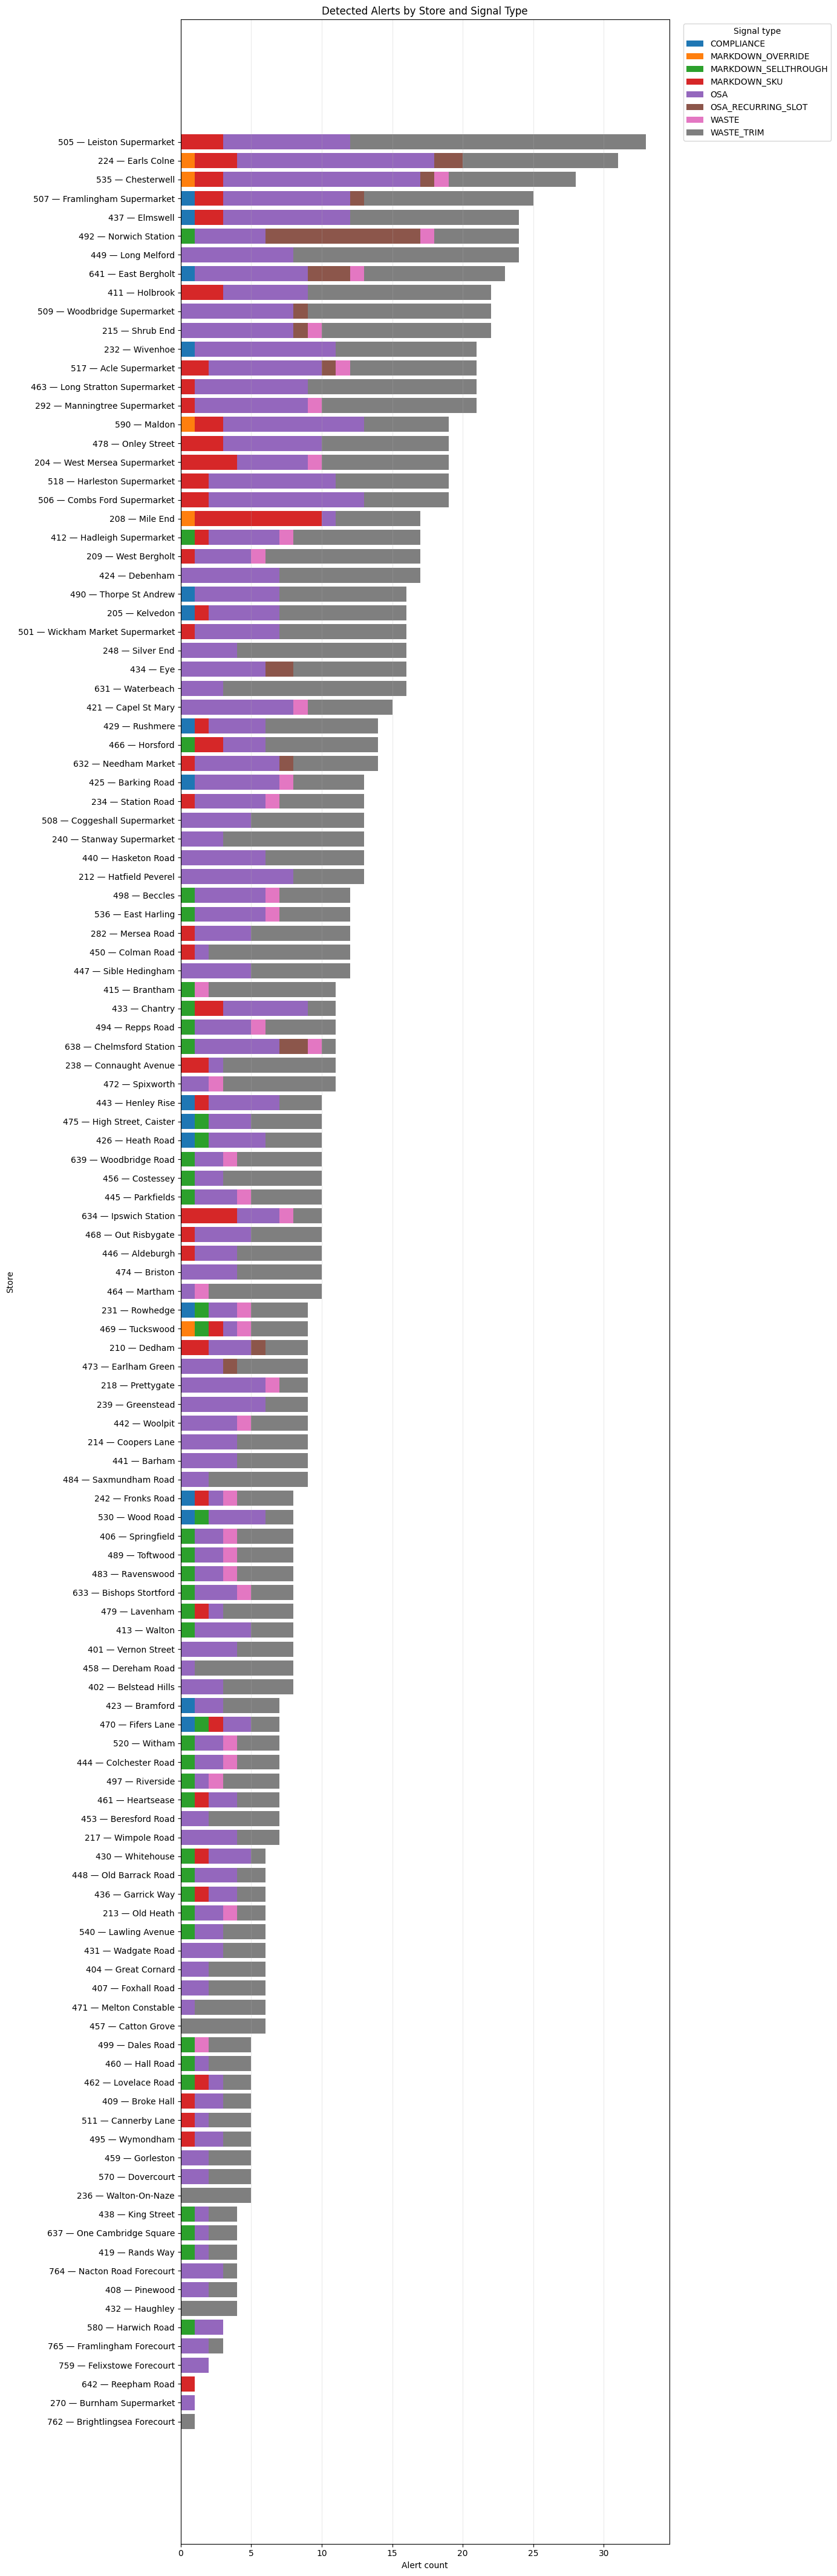

In [9]:
import matplotlib.pyplot as plt

stores = [store_id for store_id, _ in store_totals.most_common()]
labels = [f'{store_id} — {str(store_names.get(store_id) or "")[:28]}' for store_id in stores]

fig_height = max(8, len(stores) * 0.35)
fig, ax = plt.subplots(figsize=(14, fig_height))
left = [0] * len(stores)

for stype in signal_types:
    values = [store_type_counts[(store_id, stype)] for store_id in stores]
    ax.barh(labels, values, left=left, label=stype)
    left = [base + value for base, value in zip(left, values)]

ax.set_title('Detected Alerts by Store and Signal Type')
ax.set_xlabel('Alert count')
ax.set_ylabel('Store')
ax.legend(title='Signal type', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='x', alpha=0.25)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Stage 2 — Scoring: Assigns each signal a composite score (or raw projected_cost if composite is disabled). Signals are sorted by score; a top-N filter can be applied before enrichment.

In [ ]:
import copy
from store_insight.pipeline.stages._2_score.score import score_all, apply_top_n_filter

# Build a scoring_cfg dict that merges the QC overrides with whatever is in cfg.scoring
_base_scoring = cfg.scoring.model_dump() if cfg.scoring else {}
scoring_cfg = {
    **_base_scoring,
    **(
        {
            'composite_weights': COMPOSITE_WEIGHTS,
            'cost_ceilings':     COST_CEILINGS,
            'benchmark_ceilings': BENCHMARK_CEILINGS,
            'wow_ceilings':      WOW_CEILINGS,
        }
        if COMPOSITE_WEIGHTS else {}
    ),
}

# Work on a shallow copy so re-running this cell is safe
scored = [copy.copy(s) for s in signals]

score_all(
    scored,
    this_week_start=THIS_WEEK_START,
    this_week_end=THIS_WEEK_END,
    osa=osa,
    feedback=feedback,
    markdown_log=markdown_log,
    markdown_sales=markdown_sales,
    score_weights=cfg.scoring.score_weights if cfg.scoring else None,
    scoring_cfg=scoring_cfg if COMPOSITE_WEIGHTS else None,
)

scored.sort(key=lambda s: s.get('score', 0), reverse=True)

print(f'{len(scored)} signals scored')
print(f'Score range: {scored[-1]["score"]:.4f} – {scored[0]["score"]:.4f}')
print(f'Top 5 by score:')
for s in scored[:5]:
    print(f'  store={s["store_id"]:>4}  type={s["signal_type"]:<22}  triggers={"+".join(s["trigger_types"]):<35}  score={s["score"]:.4f}')

[4_score] 2803 signals scored
2803 signals scored
Score range: 0.0750 – 0.9250
Top 5 by score:
  store= 218  type=WASTE                   triggers=VS_CHAIN+WOW                         score=0.9250
  store= 218  type=MARKDOWN_SELLTHROUGH    triggers=VS_CHAIN+WOW                         score=0.7361
  store= 447  type=WASTE                   triggers=VS_CHAIN+WOW                         score=0.7343
  store= 456  type=WASTE                   triggers=VS_CHAIN                             score=0.7060
  store= 535  type=WASTE                   triggers=VS_CHAIN+WOW                         score=0.7055


In [ ]:
# ── OSA_RECURRING_SLOT scoring sanity check ────────────────────────────────────
slot_scored = [s for s in scored if s.get('signal_type') == 'OSA_RECURRING_SLOT']
print(f'OSA_RECURRING_SLOT signals scored: {len(slot_scored)}')

if slot_scored:
    slot_scored.sort(key=lambda s: s.get('score', 0), reverse=True)
    print('\nTop 5 OSA_RECURRING_SLOT by score:')
    for s in slot_scored[:5]:
        print(
            f'  store={s["store_id"]:>4}  {s["department"]:<25} '
            f'{s.get("dow_name", "?"):<10} {s.get("period_label", "?"):<22} '
            f'score={s.get("score", 0):.4f}  '
            f'projected_cost=£{s.get("projected_cost", 0):,.2f}'
        )
else:
    print('No OSA_RECURRING_SLOT signals were scored.')

OSA_RECURRING_SLOT signals scored: 0
No OSA_RECURRING_SLOT signals were scored.


In [ ]:
# ── WASTE_TRIM scoring sanity check ────────────────────────────────────────────
trim_scored = [s for s in scored if s.get('signal_type') == 'WASTE_TRIM']
print(f'WASTE_TRIM signals scored: {len(trim_scored)}')

if trim_scored:
    trim_scored.sort(key=lambda s: s.get('score', 0), reverse=True)
    print('\nTop 5 WASTE_TRIM by score:')
    for s in trim_scored[:5]:
        print(
            f'  store={s["store_id"]:>4}  item={s.get("item_id", "?"):<12} '
            f'score={s.get("score", 0):.4f}  '
            f'projected_cost=£{s.get("projected_cost", 0):,.2f}  '
            f'ratio={s.get("markdown_ratio", 0):.1%}'
        )
else:
    print('No WASTE_TRIM signals were scored.')


WASTE_TRIM signals scored: 8

Top 5 WASTE_TRIM by score:
  store= 292  item=4238         score=0.2006  projected_cost=£502.57  ratio=86.7%
  store= 270  item=4238         score=0.1487  projected_cost=£294.64  ratio=87.2%
  store= 505  item=4238         score=0.1420  projected_cost=£267.96  ratio=85.2%
  store= 407  item=4238         score=0.1083  projected_cost=£133.11  ratio=93.7%
  store= 425  item=4238         score=0.0857  projected_cost=£42.92  ratio=83.6%


In [ ]:
# Check what the financial_severity dimension receives
from store_insight.pipeline.stages._2_score.dimensions.financial_severity import score as fin_score

s = scored[0]  # First signal
projected_cost = s.get('score', 0)
ceiling = COST_CEILINGS.get(s['signal_type'], 5000)
print(f"signal_type: {s['signal_type']}")
print(f"projected_cost: {projected_cost}")
print(f"ceiling: {ceiling}")
print(f"financial_severity: {fin_score(s, projected_cost, ceiling)}")

signal_type: WASTE
projected_cost: 0.925
ceiling: 2000.0
financial_severity: 0.0004625


In [ ]:
### Inspect — Composite Dimension Breakdown (top 20 signals)
# Shows each dimension's raw score alongside the final composite score.
# Only meaningful when COMPOSITE_WEIGHTS is set.

from store_insight.pipeline.stages._2_score.dimensions import (
    financial_severity, vs_control_benchmark, vs_historical_benchmark,
    thematic, historical_recency, special_cases,
)
from store_insight.pipeline.stages._2_score import composite as _composite

if not COMPOSITE_WEIGHTS:
    print('Composite scoring is disabled — set COMPOSITE_WEIGHTS in Cell 1 to see dimension breakdown.')
else:
    rows = []
    for s in [i for i in scored if i['store_id'] == 292][:20]:
        stype        = s.get('signal_type', '')
        cost         = s.get('projected_cost', 0)   # score already IS composite; reconstruct projected_cost
        # Re-derive projected_cost from composite formula (approx — purely for display)
        fs  = financial_severity.score(s, cost, COST_CEILINGS.get(stype, 0))
        vcb = vs_control_benchmark.score(s, BENCHMARK_CEILINGS.get(stype, 0))
        vhb = vs_historical_benchmark.score(s, WOW_CEILINGS.get(stype, 0))
        th  = thematic.score(s)
        hr  = historical_recency.score(s)
        sc  = special_cases.score(s)
        rows.append({
            'store': s['store_id'],
            'type':  stype,
            'triggers': '+'.join(s.get('trigger_types', [])),
            'fin_sev':  round(fs,  3),
            'vs_ctrl':  round(vcb, 3),
            'vs_hist':  round(vhb, 3),
            'thematic': round(th,  3),
            'recency':  round(hr,  3),
            'special':  round(sc,  3),
            'composite': round(s['score'], 4),
        })

    # Pretty-print as a table
    hdr = f"{'store':>5}  {'type':<22}  {'triggers':<30}  {'fin':>5}  {'ctrl':>5}  {'hist':>5}  {'them':>5}  {'rec':>5}  {'spec':>5}  {'score':>7}"
    print(hdr)
    print('-' * len(hdr))
    for r in rows:
        print(
            f"{r['store']:>5}  {r['type']:<22}  {r['triggers']:<30}  "
            f"{r['fin_sev']:>5.3f}  {r['vs_ctrl']:>5.3f}  {r['vs_hist']:>5.3f}  "
            f"{r['thematic']:>5.3f}  {r['recency']:>5.3f}  {r['special']:>5.3f}  "
            f"{r['composite']:>7.4f}"
        )

store  type                    triggers                          fin   ctrl   hist   them    rec   spec    score
----------------------------------------------------------------------------------------------------------------
  292  WASTE_TRIM              WASTE_TRIM                      0.251  0.000  0.000  0.500  0.500  0.500   0.2006
  292  OSA                     WOW                             0.084  0.000  0.625  0.500  0.500  0.500   0.1793
  292  OSA                     WOW                             0.049  0.000  0.276  0.500  0.500  0.500   0.1271
  292  OSA                     REPEAT                          0.050  0.000  0.000  0.500  0.500  0.500   0.0999
  292  OSA                     REPEAT                          0.022  0.000  0.000  0.500  0.500  0.500   0.0858
  292  OSA                     REPEAT                          0.018  0.000  0.000  0.500  0.500  0.500   0.0841
  292  OSA                     REPEAT                          0.015  0.000  0.000  0.500  0.500

In [ ]:
# Check if wow_change_pp exists for WASTE signals
waste_signals = [s for s in scored if s.get('signal_type') == 'WASTE']
print("Store 218 WASTE fields:", [k for k in waste_signals[0].keys() if 'wow' in k.lower()])
print("wow_change_pp value:", waste_signals[0].get('wow_change_pp'))

Store 218 WASTE fields: ['wow_change_pp']
wow_change_pp value: 73.38


## Stage 3 — Fact Gathering: Enriches scored signals with department breakdowns, drilldowns, day-of-week, chain drift, history, projections.

In [ ]:
from store_insight.pipeline.stages._3_facts.facts import enrich_signals

enriched = enrich_signals(
    scored,
    osa,
    last_week_start=LAST_WEEK_START,
    last_week_end=LAST_WEEK_END,
    this_week_start=THIS_WEEK_START,
    this_week_end=THIS_WEEK_END,
    lookback_start=LOOKBACK_START,
    section='ITEM_HIERARCHY_2',
    projection_weeks=PROJECTION_WEEKS,
    drilldown_top_n=DRILLDOWN_TOP_N,
    feedback=feedback,
    markdown_log=markdown_log,
    markdown_sales=markdown_sales,
    wastage=wastage,
    item_hierarchy=wmd_item_hierarchy,
    cfg=cfg,
)

print(f'{len(enriched)} signals enriched')

[2_facts] 2803 signals enriched
2803 signals enriched


In [ ]:
### Inspect — one enriched signal per signal type
from collections import defaultdict

by_type = defaultdict(list)
for s in enriched:
    by_type[s['signal_type']].append(s)

for stype, sigs in sorted(by_type.items()):
    s = sigs[0]
    facts_keys = list(s.get('facts', {}).keys())
    print(f'{stype} (store={s["store_id"]}, score={s.get("score", "?"):.4f})')
    print(f'  facts keys : {facts_keys}')
    print()

COMPLIANCE (store=641, score=0.0750)
  facts keys : ['tf_by_alert_type']

MARKDOWN_OVERRIDE (store=408, score=0.4847)
  facts keys : ['override_dept_breakdown']

MARKDOWN_SELLTHROUGH (store=218, score=0.7361)
  facts keys : ['sellthrough_dept_breakdown']

MARKDOWN_SKU (store=282, score=0.0750)
  facts keys : ['sku_markdown_history']

OSA (store=270, score=0.5120)
  facts keys : ['subclass_contributors', 'subclass_changes', 'dow_pattern', 'worst_day', 'chain_last_week_osa', 'chain_this_week_osa', 'chain_drift_pp', 'repeat_item_history', 'day_period_pattern', 'worst_day_period', 'repeat_item_time_patterns', 'cost_projection', 'projection_weeks']

WASTE (store=218, score=0.9250)
  facts keys : ['waste_dept_breakdown']

WASTE_TRIM (store=292, score=0.2006)
  facts keys : ['chain_markdown_ratio', 'dept_markdown_ratio', 'weekly_trend']



# Stage 4 -- Investigate

In [ ]:
QC_STORE_IDS = [292]
enriched = [card for card in enriched if card['store_id'] in QC_STORE_IDS]
enriched = [card for card in enriched if card['signal_type'] == 'WASTE_TRIM']
print('number of alerts:', len(enriched))

number of alerts: 3


In [20]:
from store_insight.pipeline.stages._4_investigate.investigate import investigate
from store_insight.pipeline.stages._2_score.score import short_long_term_label

narratives = [investigate(sig, session=session, cfg=cfg) for sig in enriched]

REQUIRED_FIELDS = ['issue', 'explanation', 'cost_if_not_fixed', 'recommended_action']
blank_fields = [
    (enriched[i]['signal_type'], enriched[i]['store_id'], k)
    for i, nar in enumerate(narratives)
    for k in REQUIRED_FIELDS if not nar.get(k)
]

print(f'{len(narratives)} narratives generated')
if blank_fields:
    print(f'WARNING — {len(blank_fields)} blank fields:')
    for b in blank_fields[:10]:
        print(f'  type={b[0]}  store={b[1]}  missing={b[2]}')
else:
    print('All four fields populated for every narrative.')

3 narratives generated
All four fields populated for every narrative.


In [29]:
from store_insight.pipeline.pipeline.pipeline import _build_card

by_type = {}
for sig, nar in zip(enriched, narratives):
    stype = sig['signal_type']
    if stype not in by_type:
        label = short_long_term_label(sig)
        card  = _build_card(sig, nar, sig['score'], cfg=cfg, label=label)
        by_type[stype] = card

for stype, card in sorted(by_type.items()):
    print(f'═══ {stype} ═══')
    for k, v in card.items():
        if k in ('signal_json', 'facts_json', 'llm_prompt'):
            continue
        print(f'  {k:<22}: {v}')
    print()

═══ MARKDOWN_SKU ═══
  alert_id              : 6abb9428e3e622751ce4e37ff54a4f94826eabf2ebaf0dbaaf12768f927a84f3
  alert_type            : REPEAT_REQUEST
  store_id              : 517
  section               : FRUIT|5000128919135
  type                  : Markdown
  trigger_types         : ['REPEAT_REQUEST']
  short_long_term_label : Structural
  issue                 : FRUIT: CWS CP PLUMS PUNNET marked down 8 times in 4 weeks
  explanation           : This item has been flagged for markdown on 8 occasions over the last 4 weeks, with an average markdown depth of 41.4%. The pattern is worsening — requests increased from 2 per week to 4 in the most recent week, indicating the item is becoming harder to sell at full price.
  cost_if_not_fixed     : An item requiring markdown every week represents a recurring ordering cost and waste risk. If quantities are not adjusted, this pattern is likely to continue.
  recommended_action    : Review the ordering and ranging for CWS CP PLUMS PUNNET in F

In [ ]:
# ── OSA_RECURRING_SLOT full card preview ───────────────────────────────────────
from store_insight.pipeline.pipeline.pipeline import _build_card
from store_insight.pipeline.stages._2_score.score import short_long_term_label
from store_insight.pipeline.stages._4_investigate.investigate import investigate

if slot_example is not None:
    nar = investigate(slot_example, session=session, cfg=cfg)
    label = short_long_term_label(slot_example)
    slot_card = _build_card(slot_example, nar, slot_example['score'], cfg=cfg, label=label)

    print('═══ OSA_RECURRING_SLOT ═══')
    for k, v in slot_card.items():
        if k in ('signal_json', 'facts_json', 'llm_prompt'):
            continue
        print(f'  {k:<22}: {v}')
else:
    print('No OSA_RECURRING_SLOT example available to preview.')

In [23]:
# ── WASTE_TRIM full card preview ─────────────────────────────────────────────────
from store_insight.pipeline.pipeline.pipeline import _build_card
from store_insight.pipeline.stages._2_score.score import short_long_term_label
from store_insight.pipeline.stages._4_investigate.investigate import investigate

trim_example = None
trim_enriched = [s for s in enriched if s.get('signal_type') == 'WASTE_TRIM']

if trim_enriched:
    trim_example = max(trim_enriched, key=lambda x: x.get('score', 0))

if trim_example is not None:
    nar = investigate(trim_example, session=session, cfg=cfg)
    label = short_long_term_label(trim_example)
    trim_card = _build_card(trim_example, nar, trim_example['score'], cfg=cfg, label=label)

    print('═══ WASTE_TRIM ═══')
    for k, v in trim_card.items():
        if k in ('signal_json', 'facts_json', 'llm_prompt'):
            continue
        print(f'  {k:<22}: {v}')
else:
    print('No WASTE_TRIM example available to preview.')


═══ WASTE_TRIM ═══
  alert_id              : 271a8e34bbc3b9de91b3f2596dfbcc58b745c631170447ed296b89e2f69405e3
  alert_type            : WASTE_TRIM
  store_id              : 292
  section               : FRUIT|4238
  type                  : WASTE_TRIM
  trigger_types         : ['WASTE_TRIM']
  short_long_term_label : Structural
  issue                 : Manningtree Supermarket: CP BANANAS                in FRUIT sold 654.0% of its units at markdown this week
  explanation           : 1733 of 265 units sold were at markdown (£502.57 markdown sales).
Across all stores, this item had 658.1% markdown sales.
The FRUIT department averaged 658.1% markdown sales this week.
Weekly markdown ratio trend:
• w/c 2026-02-23: 3370/263 units (1281.4%)
• w/c 2026-03-02: 3383/241 units (1403.7%)
• w/c 2026-03-09: 2238/258 units (867.4%)
• w/c 2026-03-16: 1047/191 units (548.2%)
  cost_if_not_fixed     : If this item continues to rely on markdown clearance, it risks losing approximately £502.57 in full-pr

# Stage 4b -- LLM investigation

In [19]:
from store_insight.pipeline.stages._4_investigate import cortex

# Get top 10 signals by score
top_10 = sorted(enriched, key=lambda s: s.get('score', 0), reverse=True)[:10]

# Force cortex engine for all signal types
class CortexOverride:
    def __init__(self, sig_type):
        self.engine = 'cortex'
        self.skill_file = f'{sig_type.lower()}_skill.md'

# Generate narratives using cortex
print(f'Running Cortex LLM investigation on top {len(top_10)} signals...\n')
cortex_narratives = []
for sig in top_10:
    nar = cortex.generate(sig, session)
    cortex_narratives.append(nar)
    print(f"Store {sig['store_id']} {sig['signal_type']} (score={sig.get('score',0):.4f})")
    print(f"  Issue: {nar.get('issue', 'N/A')[:80]}...")
    print()

print(f'Cortex narratives generated for top {len(top_10)} signals.')

Running Cortex LLM investigation on top 10 signals...

Store 218 WASTE (score=0.9250)
  Issue: Straight-to-bin waste 87.8% — 59.8pp above chain average...

Store 218 MARKDOWN_SELLTHROUGH (score=0.7361)
  Issue: MARKDOWN SELL-THROUGH: 91.0% this week — 6.5pp below chain average and dropped 7...

Store 447 WASTE (score=0.7343)
  Issue: Straight-to-bin waste 83.7% — 55.7pp above chain average...

Store 456 WASTE (score=0.7060)
  Issue: STRAIGHT-TO-BIN WASTE: 52.5% rate — 24.6pp above chain average...

Store 535 WASTE (score=0.7055)
  Issue: Straight-to-bin waste 48.4% — 20.5pp above chain average...

Store 240 WASTE (score=0.6765)
  Issue: STRAIGHT-TO-BIN WASTE: 39.4% rate — 11.4pp above chain average...

Store 642 WASTE (score=0.6099)
  Issue: Straight-to-bin waste 46.7% — 18.7pp above chain average...

Store 590 WASTE (score=0.5976)
  Issue: Straight-to-bin waste 54.3% — 26.3pp above chain average...

Store 497 WASTE (score=0.5944)
  Issue: STRAIGHT-TO-BIN WASTE: 57.8% rate — 29.8pp abo

In [20]:
# Display full Cortex narratives for top 10 signals
for sig, nar in zip(top_10, cortex_narratives):
    print(f"═══ {sig['signal_type']} (Store {sig['store_id']}, Score: {sig.get('score',0):.4f}) ═══")
    print(f"  Triggers : {sig.get('trigger_types', [])}")
    print(f"  Section  : {sig.get('section', 'N/A')}")
    print()
    print(f"Issue:\n{nar.get('issue', 'N/A')}")
    print()
    print(f"Explanation:\n{nar.get('explanation', 'N/A')}")
    print()
    print(f"Cost if not fixed:\n{nar.get('cost_if_not_fixed', 'N/A')}")
    print()
    print(f"Recommended action:\n{nar.get('recommended_action', 'N/A')}")
    print()
    print("─" * 80)
    print()

═══ WASTE (Store 218, Score: 0.9250) ═══
  Triggers : ['VS_CHAIN', 'WOW']
  Section  : N/A

Issue:
Straight-to-bin waste 87.8% — 59.8pp above chain average

Explanation:
985 of 985 wasted units (87.8%) went straight to bin this week. Chain average STB rate is 28.0% — this store is 59.8pp above. Last week the rate was 14.4% — up 73.4pp.

Cost if not fixed:
If left unaddressed, items worth approximately £3,024.27 per week are being discarded that could have generated revenue through markdowns.

Recommended action:
Review end-of-life processes across all departments — ensure items flagged for markdown are being actioned before they reach their waste date. Check whether the markdown algorithm is being followed and items are not being binned before markdown is applied.

────────────────────────────────────────────────────────────────────────────────

═══ MARKDOWN_SELLTHROUGH (Store 218, Score: 0.7361) ═══
  Triggers : ['VS_CHAIN', 'WOW']
  Section  : N/A

Issue:
MARKDOWN SELL-THROUGH: 91.0%

# Saving

In [21]:
from store_insight.pipeline.pipeline.pipeline import _build_card
import json

# Build one card per enriched/narrative pair
cards = []
for sig, nar in zip(enriched, narratives):
    label = short_long_term_label(sig)
    cards.append(_build_card(sig, nar, sig['score'], cfg=cfg, label=label))

cards.sort(key=lambda x: x['sort_value'], reverse=True)

output_path = f'alerts_219_{ANALYSIS_DATE_STR}.json'
with open(output_path, 'w') as f:
    json.dump(cards, f, indent=2, default=str)

print(f'Saved {len(cards)} alert cards to {output_path}')

Saved 3 alert cards to alerts_219_2026-03-20.json


In [28]:
osa.filter(F.col('STORE_ID') == 292).filter(F.col('ITEM_CODE') == 4238).show()

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"ITEM_CODE"  |"STORE_ID"  |"ACTUAL_SALES_VOLUME"  |"LOST_SALES_VOLUME"  |"LOST_SALES_VALUE"  |"DATE"      |"DEPARTMENT_ID"  |"REPORTING_PERIOD_ID"  |"ITEM_HIERARCHY_1"  |"ITEM_HIERARCHY_2"  |"ITEM_HIERARCHY_3"  |
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|4238         |292         |5.0000                 |0.0000               |0.0000              |2026-03-19  |108              |3                      |FRUIT & VEGETABLES  |FRUIT               |CITRUS              |
|4238         |292         |7.0000                 |0.0000               |0.0000              |2026-03-19  |108              |1                 

In [30]:
markdown_sales.show()

-----------------------------------------------------------------------------------------------
|"STORE_ID"  |"UPC"          |"DATE"      |"TIME"    |"MARKDOWN_QUANTITY"  |"MARKDOWN_VALUE"  |
-----------------------------------------------------------------------------------------------
|505         |5014067451151  |2026-03-06  |14:00:00  |1.0000               |1.59              |
|505         |5016143526593  |2026-03-06  |15:00:00  |1.0000               |0.99              |
|505         |5015821127268  |2026-03-06  |15:00:00  |2.0000               |3.50              |
|505         |5015282128811  |2026-03-06  |12:00:00  |1.0000               |1.00              |
|505         |5015282127807  |2026-03-06  |18:00:00  |1.0000               |1.25              |
|505         |5014379030006  |2026-03-06  |17:00:00  |1.0000               |6.75              |
|505         |5014379012866  |2026-03-06  |13:00:00  |1.0000               |11.50             |
|505         |5014353090828  |2026-03-06

In [33]:
WASTE_TRIM_STORE_ID = 292
WASTE_TRIM_WMD_ITEM_ID = 4238

wmd_item_mapping = (
    session.table('ANALYSIS.FINAL.WMD_ITEM_HIERARCHY')
    .filter(F.col('ITEM_ID') == WASTE_TRIM_WMD_ITEM_ID)
    .select(
        F.col('ITEM_ID').alias('WMD_ITEM_ID'),
        F.col('HIERARCHY_LEVEL_1_ID').alias('OSA_ITEM_CODE'),
        F.col('ITEM_NAME'),
        F.col('SECTION'),
        F.col('SUB_SECTION'),
    )
)

print('WMD item and its OSA parent mapping')
wmd_item_mapping.show()
WASTE_TRIM_OSA_ITEM_CODE = int(wmd_item_mapping.collect()[0]['OSA_ITEM_CODE'])

osa_item = (
    osa.filter(F.col('STORE_ID') == WASTE_TRIM_STORE_ID)
    .filter(F.col('ITEM_CODE') == WASTE_TRIM_OSA_ITEM_CODE)
)
print(f'OSA rows: store {WASTE_TRIM_STORE_ID} / mapped item {WASTE_TRIM_OSA_ITEM_CODE}')
osa_item.select(
    'DATE',
    'ACTUAL_SALES_VOLUME',
    'ITEM_HIERARCHY_1',
    'ITEM_HIERARCHY_2',
    'ITEM_HIERARCHY_3',
).sort('DATE').show(100)

markdown_week = (
    markdown_sales
    .filter(F.col('STORE_ID') == WASTE_TRIM_STORE_ID)
    .filter(F.col('UPC') == WASTE_TRIM_WMD_ITEM_ID)
    .filter((F.col('DATE') >= THIS_WEEK_START) & (F.col('DATE') <= THIS_WEEK_END))
    .agg(
        F.sum('MARKDOWN_QUANTITY').alias('MARKDOWN_UNITS'),
        F.sum('MARKDOWN_VALUE').alias('MARKDOWN_VALUE'),
    )
)
osa_week = (
    osa_item
    .filter((F.col('DATE') >= THIS_WEEK_START) & (F.col('DATE') <= THIS_WEEK_END))
    .agg(F.sum('ACTUAL_SALES_VOLUME').alias('ACTUAL_SALES_UNITS'))
)

waste_trim_calculation = (
    markdown_week.cross_join(osa_week)
    .with_column(
        'TOTAL_UNITS',
        F.col('MARKDOWN_UNITS') + F.col('ACTUAL_SALES_UNITS'),
    )
    .with_column(
        'MARKDOWN_RATIO',
        F.col('MARKDOWN_UNITS') / F.col('TOTAL_UNITS'),
    )
)

print(f'WASTE_TRIM calculation for {THIS_WEEK_START} to {THIS_WEEK_END}')
print('MARKDOWN_RATIO = MARKDOWN_UNITS / (MARKDOWN_UNITS + ACTUAL_SALES_UNITS)')
waste_trim_calculation.show()


WMD item and its OSA parent mapping
-------------------------------------------------------------------------------------------
|"WMD_ITEM_ID"  |"OSA_ITEM_CODE"  |"ITEM_NAME"                |"SECTION"  |"SUB_SECTION"  |
-------------------------------------------------------------------------------------------
|4238           |747517           |CP BANANAS                 |FRUIT      |BANANAS        |
-------------------------------------------------------------------------------------------

OSA rows: store 292 / mapped item 747517
-----------------------------------------------------------------------------------------------------
|"DATE"      |"ACTUAL_SALES_VOLUME"  |"ITEM_HIERARCHY_1"  |"ITEM_HIERARCHY_2"  |"ITEM_HIERARCHY_3"  |
-----------------------------------------------------------------------------------------------------
|2026-01-10  |208.0000               |FRUIT & VEGETABLES  |FRUIT               |BANANAS             |
|2026-01-10  |14.0000                |FRUIT & VEGETABL